# Лабораторная работа 1. YOLO (Ultralytics, PyTorch) и оптимизация распознавания видеопотока

**Как запустить:** установите PyTorch под своё железо (README, шаг 1), откройте ноутбук в Jupyter / VS Code
и выполните **Run All**. На ноутбуке без видеокарты всё занимает 10–15 минут; при первом запуске нужен интернет
(веса YOLO ~5 МБ и датасет COCO128 ~7 МБ скачаются сами).

| Раздел | Пункт задания |
|---|---|
| 1 | Установить Ultralytics и запустить обученную YOLO на изображениях |
| 2 | Распознавание видеофайла |
| 3 | Сжатие изображения внутри модели (F.interpolate и слой свёртки, GPU, экспорт в ONNX) |
| 4 | Квантование модели |
| 5 | Сравнение способов ускорения (ONNX Runtime, TensorRT, OpenCV DNN, OpenVINO, CoreML …) |
| 6 | Итоги; часть на C++ — `lab1_cpp.ipynb` |

Теоретическая часть — `THEORY.md`. Реализация на C++ — папка `cpp/` и отдельный ноутбук **`lab1_cpp.ipynb`**
(собирает и запускает программу на моделях, которые создаёт этот ноутбук; запускать после него).

## 0. Установка и настройки

PyTorch ставится **до** запуска ноутбука, команда зависит от железа (README). Ячейка ниже доставит остальные
пакеты (если она что-то обновила — перезапустите ядро: Kernel → Restart). Ускорители по желанию: `openvino` (Intel/AMD CPU), `onnxruntime-gpu tensorrt` (NVIDIA),
`coremltools` (Mac), `onnxruntime-directml` (AMD Radeon на Windows) — ноутбук сам найдёт то, что установлено.

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


Параметры работы. Меняйте здесь, остальные ячейки трогать не нужно.

In [2]:
MODEL = "yolo26n.pt"          # модель Ultralytics: yolo26n.pt (по умолчанию), yolo11n.pt, yolo26s.pt ...
VIDEO = None                  # путь к своему видео; None — тестовое data/demo.mp4 (создастся автоматически)
IMGSZ = 640                   # размер входа сети
DEVICE = "auto"               # "auto" | "cpu" | "0" (NVIDIA GPU) | "mps" (Apple)
CONF, IOU = 0.25, 0.45        # порог уверенности и порог NMS
MAX_FRAMES = 150              # сколько кадров видео обрабатывать в разделах 2–3 (None — всё видео)
COMPRESS_SIZES = [0, 640, 480, 320, 256]   # раздел 3: длинная сторона после сжатия, 0 = без сжатия
CALIB_FRAMES = 64             # раздел 4: число калибровочных кадров для INT8
CALIB_METHOD = "minmax"       # "minmax" | "entropy" | "percentile"
VAL_DATA = "coco128.yaml"     # датасет для mAP; None — не считать (быстрее и без интернета)
EXTRA_FORMATS = "auto"        # раздел 4: "auto" — всё доступное из ["openvino", "engine", "coreml"]; [] — пропустить
BENCH_FRAMES = 100            # раздел 5: кадров для замера каждого бэкенда

In [3]:
import io
import logging
import os

os.environ["YOLO_VERBOSE"] = "False"  # меньше служебного вывода Ultralytics (до импорта ultralytics)
logging.getLogger("nncf").setLevel(logging.WARNING)

import platform
import re
import shutil
import sys
import tempfile
import time
import warnings
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, Markdown, display
from ultralytics import YOLO
from ultralytics.utils import ASSETS

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
MODELS, RUNS, DATA = ROOT / "models", ROOT / "runs", ROOT / "data"
for d in (MODELS, RUNS, DATA):
    d.mkdir(exist_ok=True)

if DEVICE == "auto":
    DEVICE = "0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
WEIGHTS = str(MODELS / MODEL)
STEM = Path(MODEL).stem


def ver(mod):
    try:
        return getattr(__import__(mod), "__version__", "ok")
    except Exception:
        return "не установлен"


print(f"Python {sys.version.split()[0]} ({platform.system()} {platform.machine()})")
for mod in ["torch", "ultralytics", "onnx", "onnxruntime", "cv2", "openvino", "tensorrt", "coremltools"]:
    print(f"  {mod:<12} {ver(mod)}")
print("\nУскорители:")
print(f"  PyTorch CUDA : {torch.cuda.is_available()}"
      + (f" -> {torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else ""))
print(f"  PyTorch MPS  : {torch.backends.mps.is_available()}")
print(f"  PyTorch ROCm : {getattr(torch.version, 'hip', None) is not None}")
print(f"  ONNX Runtime : {ort.get_available_providers()}")
print(f"  OpenCV CUDA  : {cv2.cuda.getCudaEnabledDeviceCount() > 0 if hasattr(cv2, 'cuda') else False}")
print(f"\nМодель: {MODEL}, устройство: {DEVICE}")

Python 3.13.18 (Linux x86_64)
  torch        2.15.0+cpu
  ultralytics  8.4.216
  onnx         1.23.2
  onnxruntime  1.32.0
  cv2          5.1.0


  openvino     2026.4.1-22982-e213a147257-releases/2026/4
  tensorrt     не установлен
  coremltools  не установлен

Ускорители:
  PyTorch CUDA : False
  PyTorch MPS  : False
  PyTorch ROCm : False
  ONNX Runtime : ['AzureExecutionProvider', 'CPUExecutionProvider']
  OpenCV CUDA  : False

Модель: yolo26n.pt, устройство: cpu


### Общие функции

Препроцессинг (letterbox), постобработка выхода YOLO (порог + NMS), отрисовка, сравнение детекций,
чтение/запись видео. Pre/post-обработка написана на NumPy + OpenCV и не зависит от Ultralytics,
поэтому одинаково работает с PyTorch, ONNX Runtime, OpenCV DNN, TensorRT и т.д.

In [4]:
COCO_NAMES = list(YOLO(WEIGHTS).names.values())  # при первом запуске здесь скачаются веса


def letterbox(img, new_shape=(640, 640), color=(114, 114, 114)):
    # Масштабирование с сохранением пропорций + серые поля до new_shape (h, w) -> (картинка, r, (pad_x, pad_y))
    h, w = img.shape[:2]
    r = min(new_shape[0] / h, new_shape[1] / w)
    nh, nw = round(h * r), round(w * r)
    if (h, w) != (nh, nw):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, left = (new_shape[0] - nh) // 2, (new_shape[1] - nw) // 2
    img = cv2.copyMakeBorder(img, top, new_shape[0] - nh - top, left, new_shape[1] - nw - left,
                             cv2.BORDER_CONSTANT, value=color)
    return img, r, (left, top)


def preprocess(frame, imgsz=IMGSZ):
    # BGR-кадр -> float32 [1,3,imgsz,imgsz], RGB, 0..1
    img, r, pad = letterbox(frame, (imgsz, imgsz))
    return cv2.dnn.blobFromImage(img, 1 / 255.0, swapRB=True), r, pad


def postprocess(out, conf=CONF, iou=IOU, r=1.0, pad=(0, 0), orig_shape=None, max_det=300):
    # Выход YOLO -> (boxes xyxy [K,4], scores [K], classes [K]) в координатах исходного кадра.
    # (1, 4+nc, N): [cx,cy,w,h, p_cls...] — нужен NMS;  (1, N, 6): [x1,y1,x2,y2,score,cls] — уже готово (NMS-free)
    out = np.asarray(out, dtype=np.float32)[0]
    if out.shape[-1] == 6:
        out = out[out[:, 4] > conf]
        boxes, scores, classes = out[:, :4].copy(), out[:, 4], out[:, 5].astype(int)
    else:
        pred = out.T
        classes = pred[:, 4:].argmax(1)
        scores = pred[np.arange(len(pred)), 4 + classes]
        keep = scores > conf
        pred, classes, scores = pred[keep], classes[keep], scores[keep]
        boxes = np.concatenate([pred[:, :2] - pred[:, 2:4] / 2, pred[:, :2] + pred[:, 2:4] / 2], 1)
        if len(boxes):  # NMS по классам: рамки разных классов разносим далеко друг от друга
            off = boxes + classes[:, None] * 7680.0
            xywh = np.concatenate([off[:, :2], off[:, 2:] - off[:, :2]], 1)
            idx = np.array(cv2.dnn.NMSBoxes(xywh.tolist(), scores.tolist(), conf, iou, top_k=max_det), int).reshape(-1)
            boxes, scores, classes = boxes[idx], scores[idx], classes[idx]
    boxes[:, [0, 2]] = (boxes[:, [0, 2]] - pad[0]) / r
    boxes[:, [1, 3]] = (boxes[:, [1, 3]] - pad[1]) / r
    if orig_shape is not None:
        boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, orig_shape[1])
        boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, orig_shape[0])
    return boxes, scores, classes


PALETTE = [(214, 120, 42), (52, 104, 235), (122, 175, 27), (0, 161, 237), (164, 123, 232), (0, 131, 0)]


def draw(frame, boxes, scores, classes, names=COCO_NAMES, info=None):
    for (x1, y1, x2, y2), s, c in zip(boxes.astype(int), scores, classes):
        col = PALETTE[int(c) % len(PALETTE)]
        cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
        label = f"{names[c]} {s:.2f}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(frame, (x1, max(y1 - th - 6, 0)), (x1 + tw + 4, max(y1, th + 6)), col, -1)
        cv2.putText(frame, label, (x1 + 2, max(y1 - 4, th + 2)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    if info:
        cv2.putText(frame, info, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4)
        cv2.putText(frame, info, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
    return frame


def box_iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), np.float32)
    lt, rb = np.maximum(a[:, None, :2], b[None, :, :2]), np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.prod((rb - lt).clip(0), axis=2)
    return inter / (np.prod(a[:, 2:] - a[:, :2], 1)[:, None] + np.prod(b[:, 2:] - b[:, :2], 1)[None] - inter + 1e-9)


def count_matches(ref, test, iou_thr=0.5):
    # Сколько эталонных объектов найдено и в test (тот же класс, IoU >= 0.5)
    (rb, _, rc), (tb, _, tc) = ref, test
    if len(rb) == 0 or len(tb) == 0:
        return 0
    ious = box_iou(rb, tb) * (rc[:, None] == tc[None, :])
    used, matched = set(), 0
    for i in np.argsort(-ious.max(1)):
        j = int(ious[i].argmax())
        if ious[i, j] >= iou_thr and j not in used:
            used.add(j)
            matched += 1
    return matched


def agreement(ref_dets, dets):
    n_ref = sum(len(d[0]) for d in ref_dets)
    return 100 * sum(count_matches(r, d) for r, d in zip(ref_dets, dets)) / max(n_ref, 1)


class Timer:
    def __enter__(self):
        self.t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        self.ms = (time.perf_counter() - self.t0) * 1000


def open_video(source):
    cap = cv2.VideoCapture(int(source) if str(source).isdigit() else str(source))
    if not cap.isOpened():
        raise FileNotFoundError(f"Не удалось открыть видео: {source}")
    return cap


def make_writer(path, fps, w, h):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    return cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), fps or 25, (w, h))


def read_frames(source, n, stride=None):
    # До n кадров, равномерно по всему видео (stride=1 — подряд с начала)
    cap = open_video(source)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) or n
    stride = stride or max(total // n, 1)
    frames, i = [], 0
    while len(frames) < n:
        ok, f = cap.read()
        if not ok:
            break
        if i % stride == 0:
            frames.append(f)
        i += 1
    cap.release()
    return frames


def file_mb(path):
    p = Path(path)
    return (sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size) / 1e6


def table(rows, cols=None, save=None):
    # Список словарей -> таблица Markdown (показать в ноутбуке и сохранить в файл)
    cols = cols or [c for c in rows[0] if not c.startswith("_")]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(r.get(c, "")) for c in cols) + " |" for r in rows]
    text = "\n".join(lines)
    if save:
        Path(save).parent.mkdir(parents=True, exist_ok=True)
        Path(save).write_text(text + "\n", encoding="utf-8")
    display(Markdown(text))
    return text


def show(images, titles=None, cols=2, width=7):
    # Показать BGR-картинки сеткой
    cols = min(cols, len(images))
    rows = (len(images) + cols - 1) // cols
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(width * cols, rows * (width * h / w + 0.4)))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = np.atleast_1d(axes).ravel()[i]
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if titles:
            ax.set_title(titles[i], fontsize=11, color="#0b0b0b")
    plt.tight_layout()
    buf = io.BytesIO()  # фото показываем в JPEG — ноутбук с результатами остаётся лёгким
    fig.savefig(buf, format="jpg", dpi=80, pil_kwargs={"quality": 85})
    plt.close(fig)
    display(Image(data=buf.getvalue()))


def rel(p):
    # Путь относительно папки ноутбука — для коротких сообщений
    try:
        return str(Path(p).resolve().relative_to(ROOT))
    except ValueError:
        return str(p)


def video_frames(path, positions=(0.15, 0.4, 0.65, 0.9)):
    cap = open_video(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    out = []
    for p in positions:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(p * (n - 1)))
        ok, f = cap.read()
        if ok:
            out.append(f)
    cap.release()
    return out


def make_ort_session(path, providers=None):
    # Сессия ONNX Runtime с максимальной оптимизацией графа; если ускоритель не запустился — CPU
    providers = providers or ["CPUExecutionProvider"]
    so = ort.SessionOptions()
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    names = [p[0] if isinstance(p, tuple) else p for p in providers]
    if "DmlExecutionProvider" in names:  # требование DirectML
        so.enable_mem_pattern = False
        so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    try:
        return ort.InferenceSession(str(path), so, providers=providers)
    except Exception as e:
        if names == ["CPUExecutionProvider"]:
            raise
        print(f"[!] {names[0]} не запустился ({type(e).__name__}) — использую CPU")
        return ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])


def gpu_providers():
    av = ort.get_available_providers()
    return [p for p in ["CUDAExecutionProvider", "CoreMLExecutionProvider", "DmlExecutionProvider"] if p in av] + [
        "CPUExecutionProvider"]


def export_model(fmt, dst, quantize=None, **kw):
    # Экспорт Ultralytics в dst. Экспортируем из временной копии весов: Ultralytics кладёт результат
    # (и промежуточный ONNX для TensorRT/OpenVINO) рядом с весами — так варианты не затирают друг друга.
    dst = Path(dst)
    if dst.exists():
        return dst
    with tempfile.TemporaryDirectory(dir=MODELS) as tmp:
        w = Path(tmp) / Path(WEIGHTS).name
        shutil.copy(WEIGHTS, w)
        out = Path(YOLO(str(w)).export(format=fmt, quantize=quantize, verbose=False, **kw))
        shutil.move(str(out), str(dst))
    return dst


def cpu_name():
    try:
        if platform.system() == "Linux":
            for line in open("/proc/cpuinfo", encoding="utf-8"):
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
        if platform.system() == "Darwin":
            import subprocess
            return subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
    except Exception:
        pass
    return platform.processor() or platform.machine()


# Цвета графиков: один оттенок для данных, серый — для второстепенного
ACCENT, MUTED, INK, INK2 = "#2a78d6", "#b9b8b2", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
                     "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})
print("Функции готовы. Классов в модели:", len(COCO_NAMES))

Функции готовы. Классов в модели: 80


## 1. Запуск обученной YOLO на изображениях

`YOLO("yolo26n.pt")` загружает сеть, предобученную на COCO (80 классов). На картинках из пакета Ultralytics:
`bus.jpg` — автобус и люди, `zidane.jpg` — двое людей и галстук. Для своей картинки замените список `sources`.

yolo26n.pt: 260 слоёв, 2.57 млн параметров, 6.2 GFLOPs при 640x640



bus.jpg: 5 объектов | препроцессинг 3.7 мс, инференс 74.1 мс, постпроцессинг 0.7 мс
   bus          conf=0.90  box=(10, 231, 801, 748)
   person       conf=0.85  box=(47, 398, 238, 902)
   person       conf=0.85  box=(224, 407, 346, 861)
   person       conf=0.84  box=(669, 387, 810, 880)
   person       conf=0.56  box=(0, 553, 60, 873)

zidane.jpg: 3 объектов | препроцессинг 3.7 мс, инференс 74.1 мс, постпроцессинг 0.7 мс
   person       conf=0.90  box=(743, 40, 1151, 708)
   person       conf=0.79  box=(120, 203, 986, 713)
   tie          conf=0.59  box=(437, 435, 526, 716)


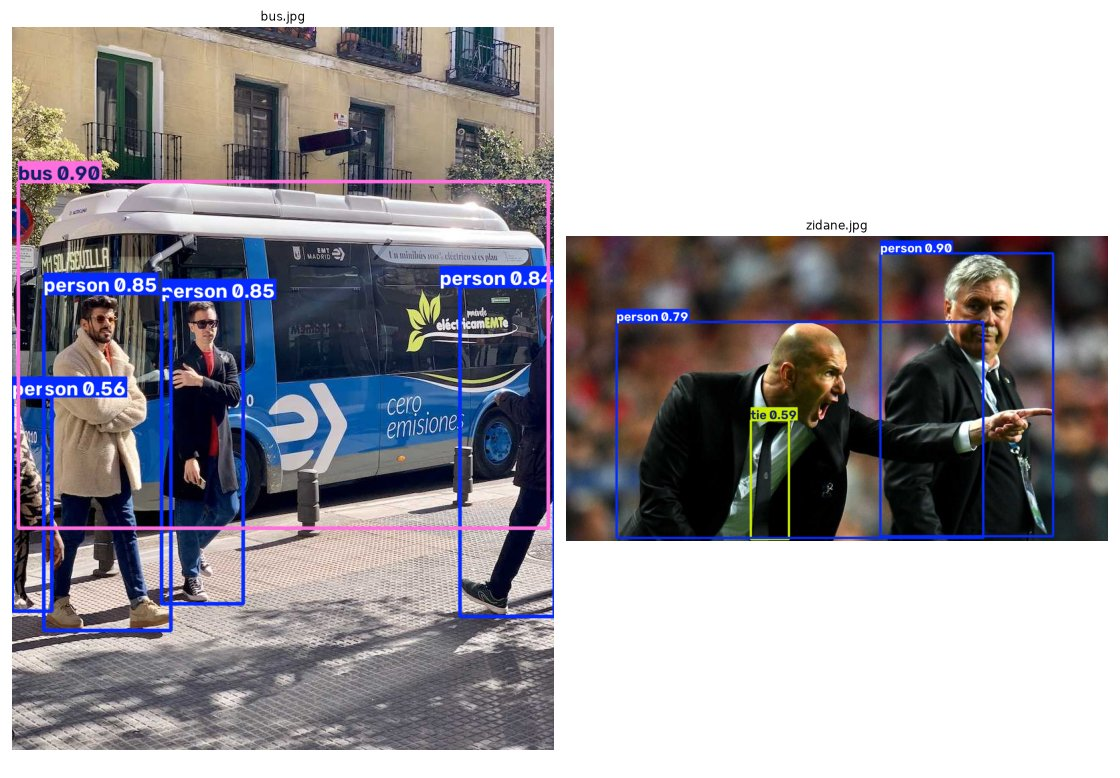

In [5]:
model = YOLO(WEIGHTS)
layers, params, _, gflops = model.info()  # (печать Ultralytics отключена, выводим сами)
print(f"{MODEL}: {layers} слоёв, {params / 1e6:.2f} млн параметров, {gflops:.1f} GFLOPs при 640x640")

sources = [str(ASSETS / "bus.jpg"), str(ASSETS / "zidane.jpg")]
model.predict(sources[0], imgsz=IMGSZ, device=DEVICE, verbose=False)  # прогрев: первый вызов всегда медленнее
results = model.predict(sources, imgsz=IMGSZ, conf=CONF, device=DEVICE, verbose=False,
                        save=True, project=str(RUNS), name="01_images", exist_ok=True)
for r in results:
    s = r.speed
    print(f"\n{Path(r.path).name}: {len(r.boxes)} объектов | препроцессинг {s['preprocess']:.1f} мс, "
          f"инференс {s['inference']:.1f} мс, постпроцессинг {s['postprocess']:.1f} мс")
    for b in r.boxes:
        x1, y1, x2, y2 = (round(v) for v in b.xyxy[0].tolist())
        print(f"   {r.names[int(b.cls)]:<12} conf={float(b.conf):.2f}  box=({x1}, {y1}, {x2}, {y2})")

show([r.plot() for r in results], [Path(r.path).name for r in results])

## 2. Распознавание видеофайла

Если `VIDEO = None`, создаётся тестовое видео `data/demo.mp4` (1280×720, 12 с): «камера» едет и приближается
по двум картинкам из Ultralytics, поэтому объекты двигаются и меняют размер. Можно указать своё видео
или веб-камеру (`VIDEO = "0"`).

Конвейер: чтение кадра (OpenCV) → YOLO → отрисовка → запись в `runs/02_video/`. Время меряется по этапам.

In [6]:
def make_demo_video(out=DATA / "demo.mp4", W=1280, H=720, fps=25, seconds=12):
    imgs = [cv2.imread(str(ASSETS / "bus.jpg")), cv2.imread(str(ASSETS / "zidane.jpg"))]
    aspect = W / H

    def ken_burns(img, t, z0, z1, p0, p1):  # окно с плавным зумом и панорамой, t in [0,1]
        ih, iw = img.shape[:2]
        e = 0.5 - 0.5 * np.cos(np.pi * t)
        z = z0 + (z1 - z0) * e
        cw = min(iw, ih * aspect) / z
        ch = cw / aspect
        x0 = int((iw - cw) * (p0[0] + (p1[0] - p0[0]) * e))
        y0 = int((ih - ch) * (p0[1] + (p1[1] - p0[1]) * e))
        return cv2.resize(img[y0:y0 + int(ch), x0:x0 + int(cw)], (W, H), interpolation=cv2.INTER_AREA)

    segments = [(0, 1.0, 1.6, (0.5, 0.2), (0.2, 0.6)), (0, 1.6, 1.1, (0.2, 0.6), (0.9, 0.9)),
                (1, 1.0, 1.8, (0.5, 0.5), (0.85, 0.3)), (1, 1.8, 1.2, (0.85, 0.3), (0.1, 0.6))]
    per_seg = int(fps * seconds) // len(segments)
    writer, rng = cv2.VideoWriter(str(out), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H)), np.random.default_rng(0)
    for img_id, z0, z1, p0, p1 in segments:
        for i in range(per_seg):
            f = ken_burns(imgs[img_id], i / (per_seg - 1), z0, z1, p0, p1).astype(np.int16)
            writer.write(np.clip(f + rng.normal(0, 3, f.shape).astype(np.int16), 0, 255).astype(np.uint8))
    writer.release()
    return str(out)


if VIDEO is None:
    VIDEO = str(DATA / "demo.mp4")
    if not Path(VIDEO).exists():
        make_demo_video()
cap = open_video(VIDEO)
VW, VH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"Видео: {rel(VIDEO)}  {VW}x{VH}, {cap.get(cv2.CAP_PROP_FPS):.1f} к/с, кадров: {int(cap.get(cv2.CAP_PROP_FRAME_COUNT))}")
cap.release()

Видео: data/demo.mp4  1280x720, 25.0 к/с, кадров: 300


Обработано кадров: 150
  read            1.15 мс
  preprocess      1.64 мс
  inference      47.12 мс
  postprocess     0.83 мс
  draw+write      7.52 мс
FPS модели: 20.2;  FPS всего конвейера (с чтением, отрисовкой, записью): 17.0
Максимум объектов на кадре: {'person': 4, 'car': 2, 'fire hydrant': 2, 'bus': 1, 'stop sign': 1, 'truck': 1, 'handbag': 1, 'teddy bear': 1, 'airplane': 1, 'skateboard': 1}
Видео с разметкой: runs/02_video/yolo26n_640.mp4


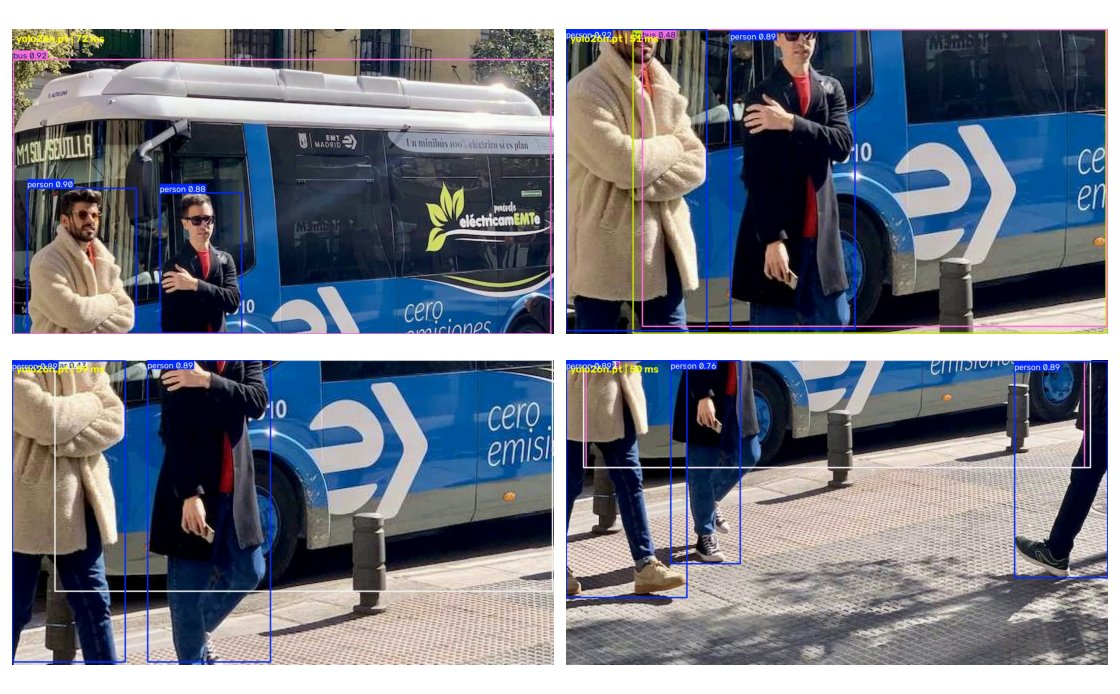

In [7]:
def detect_video(weights, source, out_path, imgsz=IMGSZ, vid_stride=1, max_frames=MAX_FRAMES, fp16=False):
    model = YOLO(str(weights), task="detect")
    kw = dict(imgsz=imgsz, conf=CONF, iou=IOU, device=DEVICE, verbose=False)
    if fp16:
        kw["quantize"] = 16  # в Ultralytics 8.4 quantize=16 заменил устаревший half=True (только GPU)
    cap = open_video(source)
    fps_in = cap.get(cv2.CAP_PROP_FPS) or 25
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = make_writer(out_path, fps_in / vid_stride, w, h)
    ok, frame = cap.read()
    for _ in range(3):  # прогрев: первые вызовы медленные (выделение памяти, выбор ядер)
        model.predict(frame, **kw)
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    st = {k: [] for k in ("read", "preprocess", "inference", "postprocess", "draw+write")}
    max_per_frame, n, idx = Counter(), 0, -1
    t_start = time.perf_counter()
    while True:
        with Timer() as t:
            ok, frame = cap.read()
        if not ok:
            break
        st["read"].append(t.ms)
        idx += 1
        if idx % vid_stride:
            continue
        r = model.predict(frame, **kw)[0]
        for k in ("preprocess", "inference", "postprocess"):
            st[k].append(r.speed[k])
        with Timer() as t:
            ms = sum(r.speed.values())
            img = r.plot(line_width=2)
            cv2.putText(img, f"{Path(str(weights)).name} | {ms:.0f} ms", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8,
                        (0, 255, 255), 2)
            writer.write(img)
        st["draw+write"].append(t.ms)
        for k, v in Counter(r.names[int(c)] for c in r.boxes.cls).items():
            max_per_frame[k] = max(max_per_frame[k], v)
        n += 1
        if max_frames and n >= max_frames:
            break
    wall = time.perf_counter() - t_start
    cap.release()
    writer.release()
    ms = {k: float(np.mean(v)) for k, v in st.items()}
    model_ms = ms["preprocess"] + ms["inference"] + ms["postprocess"]
    return {"frames": n, "ms": ms, "fps_model": 1000 / model_ms, "fps_pipeline": n / wall,
            "objects": dict(max_per_frame.most_common()), "out": str(out_path)}


base = detect_video(WEIGHTS, VIDEO, RUNS / "02_video" / f"{STEM}_{IMGSZ}.mp4")
print(f"Обработано кадров: {base['frames']}")
for k, v in base["ms"].items():
    print(f"  {k:<12} {v:7.2f} мс")
print(f"FPS модели: {base['fps_model']:.1f};  FPS всего конвейера (с чтением, отрисовкой, записью): {base['fps_pipeline']:.1f}")
print("Максимум объектов на кадре:", base["objects"])
print("Видео с разметкой:", rel(base["out"]))
show(video_frames(base["out"]), cols=2)

Те же кадры с простыми приёмами ускорения средствами Ultralytics: уменьшение входа сети и пропуск кадров
(на GPU добавляется FP16).

In [8]:
variants = [("640, каждый кадр", base)]
variants.append(("320, каждый кадр", detect_video(WEIGHTS, VIDEO, RUNS / "02_video" / f"{STEM}_320.mp4", imgsz=320)))
variants.append(("640, каждый 2-й кадр", detect_video(WEIGHTS, VIDEO, RUNS / "02_video" / f"{STEM}_stride2.mp4",
                                                     vid_stride=2, max_frames=(MAX_FRAMES or 10**9) // 2)))
if DEVICE != "cpu":
    variants.append(("640, FP16 на GPU", detect_video(WEIGHTS, VIDEO, RUNS / "02_video" / f"{STEM}_fp16.mp4", fp16=True)))
table([{"Вариант": name, "Инференс, мс": f"{v['ms']['inference']:.1f}", "Pre+post, мс":
        f"{v['ms']['preprocess'] + v['ms']['postprocess']:.1f}", "FPS модели": f"{v['fps_model']:.1f}",
        "FPS конвейера": f"{v['fps_pipeline']:.1f}", "Кадров": v["frames"]} for name, v in variants],
      save=RUNS / "02_video" / "results.md")

| Вариант | Инференс, мс | Pre+post, мс | FPS модели | FPS конвейера | Кадров |
|---|---|---|---|---|---|
| 640, каждый кадр | 47.1 | 2.5 | 20.2 | 17.0 | 150 |
| 320, каждый кадр | 16.1 | 1.2 | 58.1 | 38.7 | 150 |
| 640, каждый 2-й кадр | 54.3 | 2.8 | 17.5 | 14.2 | 75 |

'| Вариант | Инференс, мс | Pre+post, мс | FPS модели | FPS конвейера | Кадров |\n|---|---|---|---|---|---|\n| 640, каждый кадр | 47.1 | 2.5 | 20.2 | 17.0 | 150 |\n| 320, каждый кадр | 16.1 | 1.2 | 58.1 | 38.7 | 150 |\n| 640, каждый 2-й кадр | 54.3 | 2.8 | 17.5 | 14.2 | 75 |'

## 3. Сжатие изображения внутри модели (с поддержкой GPU)

Задача: кадр **фиксированного размера** (размер видео не меняется) подаётся в модель как есть, а сжимает его
**сама модель** — первыми слоями своего графа. Переобучать ничего не нужно: веса YOLO не меняются, а у слоя
сжатия веса задаются, а не обучаются. Модель изменяется так — перед YOLO добавляются слои:

```
кадр uint8 [1,H,W,3] (как есть из cv2.VideoCapture)
  → BGR→RGB, uint8→float                                   (Transpose, Cast, Gather)
  → СЖАТИЕ до длинной стороны S — один из двух способов:
       method="interpolate":  F.interpolate (bilinear)       → узел Resize
       method="conv":         слой свёртки Conv2d k×k, шаг k  → узел Conv
                              (depthwise, веса = 1/k², т.е. усреднение блока; при нецелом коэффициенте
                               остаток досжимается F.interpolate)
  → поля до кратного 32 (шаг сети), /255                   (Pad, Div)
  → YOLO
  → рамки пересчитываются обратно в координаты исходного кадра
```

Оба способа — стандартные операции, которые выполняются на GPU: в PyTorch модель целиком переносится
на `cuda`/`mps` вызовом `.to(DEVICE)`, в ONNX Runtime узлы Resize и Conv исполняет CUDA EP (TensorRT, CoreML,
DirectML). На машине без видеокарты всё работает на CPU — тот же код.

Различие способов: `F.interpolate` берёт билинейно 2×2 соседних пикселя, при сжатии больше чем в 2 раза
часть пикселей пропускается (алиасинг, «лесенки»); свёртка k×k усредняет все пиксели блока — сглаживает
шум и мелкие детали, но считает больше операций на полном кадре.

Ниже: построение изменённой модели, **проверка экспорта в ONNX** (onnx.checker, узлы сжатия в графе,
совпадение с PyTorch), запуск на `DEVICE`, сравнение скорости и качества на видео.

In [9]:
from ultralytics.nn.modules import Detect

METHODS = ["interpolate", "conv"]


class CompressedInputYOLO(nn.Module):
    # Изменённая YOLO: принимает кадр фиксированного размера uint8 [1,H,W,3] BGR и сама сжимает его
    # до длинной стороны target способом method ("interpolate" или "conv"). Все операции — GPU-совместимые.

    def __init__(self, det_model, frame_hw, target, method="interpolate", stride=32):
        super().__init__()
        H, W = frame_hw
        r = 1.0 if target <= 0 else min(1.0, target / max(H, W))
        self.nh, self.nw = round(H * r), round(W * r)                 # размер после сжатия
        self.method = method
        self.k = max(int(1 / r), 1) if method == "conv" else 1        # шаг свёртки (целый коэффициент)
        self.down = None
        if self.k > 1:  # слой свёртки: depthwise Conv2d k×k, шаг k, веса 1/k² (усреднение блока), без обучения
            self.down = nn.Conv2d(3, 3, kernel_size=self.k, stride=self.k, groups=3, bias=False)
            self.down.weight.data.fill_(1.0 / self.k ** 2)
            self.down.weight.requires_grad_(False)
        self.ph, self.pw = (-self.nh) % stride, (-self.nw) % stride    # поля до кратного stride
        self.net_hw = (self.nh + self.ph, self.nw + self.pw)           # фактический вход сети
        self.model = det_model
        sx, sy = W / self.nw, H / self.nh
        self.register_buffer("scale_cxcywh", torch.tensor([sx, sy, sx, sy]).view(1, 4, 1))
        self.register_buffer("scale_xyxy", torch.tensor([sx, sy, sx, sy]).view(1, 1, 4))

    def forward(self, frame):
        x = frame.permute(0, 3, 1, 2).float()[:, [2, 1, 0]]          # NHWC uint8 BGR -> NCHW float RGB
        if self.down is not None:
            x = self.down(x)                                           # сжатие свёрткой
        if tuple(x.shape[-2:]) != (self.nh, self.nw):
            x = F.interpolate(x, size=(self.nh, self.nw), mode="bilinear", align_corners=False)  # сжатие Resize
        if self.ph or self.pw:
            x = F.pad(x, (0, self.pw, 0, self.ph), value=114.0)      # серые поля справа/снизу
        y = self.model(x / 255.0)
        if y.shape[-1] == 6:                                           # end-to-end выход [x1,y1,x2,y2,score,cls]
            return torch.cat([y[..., :4] * self.scale_xyxy, y[..., 4:]], -1)
        return torch.cat([y[:, :4] * self.scale_cxcywh, y[:, 4:]], 1)


def load_export_ready(weights):
    # YOLO в «режиме экспорта», как это делает Ultralytics Exporter: склейка Conv+BN, один выходной тензор
    y = YOLO(weights)
    m = y.model.float().eval()
    for p in m.parameters():
        p.requires_grad = False
    m = m.fuse()
    for mod in m.modules():
        if isinstance(mod, Detect):
            mod.export, mod.format, mod.dynamic = True, "onnx", False
        if type(mod).__name__ == "SPPF" and hasattr(mod, "export"):
            mod.export = True
    return m, y.names


def export_compressed(module, frame_hw, path, names):
    # Экспорт изменённой модели в ONNX + проверка onnx.checker; возвращает операции блока сжатия
    dummy = torch.zeros(1, *frame_hw, 3, dtype=torch.uint8)
    torch.onnx.export(module.cpu(), dummy, str(path), opset_version=17, input_names=["frame"],
                      output_names=["output0"], do_constant_folding=True, dynamo=False)
    m = onnx.load(str(path))
    try:
        import onnxslim
        m = onnxslim.slim(m)
    except Exception:
        pass
    for k, v in {"names": str(names), "frame_hw": str(list(frame_hw)), "net_hw": str(list(module.net_hw)),
                 "compress": module.method}.items():
        m.metadata_props.add(key=k, value=v)
    onnx.checker.check_model(m)  # граф корректен с точки зрения стандарта ONNX
    onnx.save(m, str(path))
    return [n.op_type for n in m.graph.node if not n.name.startswith("/model/")]  # узлы до YOLO


det_model, names = load_export_ready(WEIGHTS)
frame0 = read_frames(VIDEO, 1, stride=1)[0]
compressed, export_rows = [], []
for S in COMPRESS_SIZES:
    for method in (["interpolate"] if S <= 0 else METHODS):  # без сжатия способ не важен
        m = CompressedInputYOLO(det_model, (VH, VW), S, method).eval()
        tag = "full" if S <= 0 else f"{method}_{VW}x{VH}_to_{S}"
        path = MODELS / (f"{STEM}_compressed_{VW}x{VH}_to_full.onnx" if S <= 0 else f"{STEM}_compressed_{tag}.onnx")
        ops = export_compressed(m, (VH, VW), path, names)
        with torch.no_grad():
            y_torch = m(torch.from_numpy(frame0[None])).numpy()
        y_ort = make_ort_session(path).run(None, {"frame": frame0[None]})[0]
        compressed.append((S, method if S > 0 else "—", m.net_hw, path))
        ops_c = [o for o in ops if o in ("Conv", "Resize")]
        export_rows.append({"Сжатие до": S or "нет", "Способ": method if S > 0 else "—",
                            "Вход сети": f"{m.net_hw[1]}x{m.net_hw[0]}", "Слой сжатия в ONNX": " + ".join(ops_c) or "—",
                            "onnx.checker": "OK", "Макс. разница PyTorch и ORT, пикс.": f"{np.abs(y_torch - y_ort).max():.4f}",
                            "Файл": path.name})
table(export_rows, save=RUNS / "03_compress" / "export_check.md")

| Сжатие до | Способ | Вход сети | Слой сжатия в ONNX | onnx.checker | Макс. разница PyTorch и ORT, пикс. | Файл |
|---|---|---|---|---|---|---|
| нет | — | 1280x736 | — | OK | 0.0027 | yolo26n_compressed_1280x720_to_full.onnx |
| 640 | interpolate | 640x384 | Resize | OK | 0.0026 | yolo26n_compressed_interpolate_1280x720_to_640.onnx |
| 640 | conv | 640x384 | Conv | OK | 0.0026 | yolo26n_compressed_conv_1280x720_to_640.onnx |
| 480 | interpolate | 480x288 | Resize | OK | 0.0825 | yolo26n_compressed_interpolate_1280x720_to_480.onnx |
| 480 | conv | 480x288 | Conv + Resize | OK | 0.0179 | yolo26n_compressed_conv_1280x720_to_480.onnx |
| 320 | interpolate | 320x192 | Resize | OK | 0.0018 | yolo26n_compressed_interpolate_1280x720_to_320.onnx |
| 320 | conv | 320x192 | Conv | OK | 0.0043 | yolo26n_compressed_conv_1280x720_to_320.onnx |
| 256 | interpolate | 256x160 | Resize | OK | 0.0048 | yolo26n_compressed_interpolate_1280x720_to_256.onnx |
| 256 | conv | 256x160 | Conv | OK | 0.0043 | yolo26n_compressed_conv_1280x720_to_256.onnx |

'| Сжатие до | Способ | Вход сети | Слой сжатия в ONNX | onnx.checker | Макс. разница PyTorch и ORT, пикс. | Файл |\n|---|---|---|---|---|---|---|\n| нет | — | 1280x736 | — | OK | 0.0027 | yolo26n_compressed_1280x720_to_full.onnx |\n| 640 | interpolate | 640x384 | Resize | OK | 0.0026 | yolo26n_compressed_interpolate_1280x720_to_640.onnx |\n| 640 | conv | 640x384 | Conv | OK | 0.0026 | yolo26n_compressed_conv_1280x720_to_640.onnx |\n| 480 | interpolate | 480x288 | Resize | OK | 0.0825 | yolo26n_compressed_interpolate_1280x720_to_480.onnx |\n| 480 | conv | 480x288 | Conv + Resize | OK | 0.0179 | yolo26n_compressed_conv_1280x720_to_480.onnx |\n| 320 | interpolate | 320x192 | Resize | OK | 0.0018 | yolo26n_compressed_interpolate_1280x720_to_320.onnx |\n| 320 | conv | 320x192 | Conv | OK | 0.0043 | yolo26n_compressed_conv_1280x720_to_320.onnx |\n| 256 | interpolate | 256x160 | Resize | OK | 0.0048 | yolo26n_compressed_interpolate_1280x720_to_256.onnx |\n| 256 | conv | 256x160 | Conv | OK |

In [10]:
# Изменённая модель — обычный nn.Module, поэтому целиком переносится на GPU (CUDA / Apple MPS).
dev = torch.device("cuda:0" if DEVICE == "0" else DEVICE)
x = torch.from_numpy(frame0[None]).to(dev)  # кадр uint8 копируется на устройство как есть — в 4 раза меньше float32
rows_dev = []
for method in METHODS:
    m = CompressedInputYOLO(det_model, (VH, VW), 320, method).eval().to(dev)
    with torch.inference_mode():
        for _ in range(3):
            m(x)
        ts = []
        for _ in range(20):
            with Timer() as t:
                y = m(x)
                if dev.type == "cuda":
                    torch.cuda.synchronize()
                elif dev.type == "mps":
                    torch.mps.synchronize()
            ts.append(t.ms)
    rows_dev.append({"Способ": method, "Устройство PyTorch": str(dev), "Параметры на устройстве":
                     str(next(m.parameters()).device), "Выход на устройстве": str(y.device),
                     "Время, мс (сжатие до 320)": f"{np.mean(ts):.1f}"})
det_model.cpu()
table(rows_dev)
print("ONNX Runtime providers для разделов ниже:", gpu_providers())

| Способ | Устройство PyTorch | Параметры на устройстве | Выход на устройстве | Время, мс (сжатие до 320) |
|---|---|---|---|---|
| interpolate | cpu | cpu | cpu | 26.9 |
| conv | cpu | cpu | cpu | 39.8 |

ONNX Runtime providers для разделов ниже: ['CPUExecutionProvider']


In [11]:
REF = (640 if 640 in COMPRESS_SIZES else COMPRESS_SIZES[-1], "interpolate")  # эталон: обычный препроцессинг до 640
providers = gpu_providers()
res3 = {}
for S, method, net_hw, path in compressed:
    sess = make_ort_session(path, providers)
    for _ in range(3):
        sess.run(None, {"frame": frame0[None]})
    t_inf, t_post, dets = [], [], []
    name = path.stem.replace(f"{STEM}_compressed_", "")
    writer = make_writer(RUNS / "03_compress" / f"{name}.mp4", 25, VW, VH)
    cap = open_video(VIDEO)
    while not MAX_FRAMES or len(dets) < MAX_FRAMES:
        ok, f = cap.read()
        if not ok:
            break
        with Timer() as t:                       # весь препроцессинг + сжатие + сеть — один вызов
            out = sess.run(None, {"frame": f[None]})[0]
        t_inf.append(t.ms)
        with Timer() as t:                       # в Python остаётся только NMS
            d = postprocess(out, orig_shape=(VH, VW))
        t_post.append(t.ms)
        dets.append(d)
        writer.write(draw(f, *d, info=f"{method} -> {net_hw[1]}x{net_hw[0]}, {t.ms + t_inf[-1]:.0f} ms"))
    cap.release()
    writer.release()
    res3[(S, method)] = {"net_hw": net_hw, "inf": np.mean(t_inf), "post": np.mean(t_post), "dets": dets,
                         "video": RUNS / "03_compress" / f"{name}.mp4"}
    print(f"сжатие до {S or 'нет':>4} {method:<12} {np.mean(t_inf):6.1f} мс")

ref_dets = res3[(REF[0], "interpolate")]["dets"]
rows3 = []
for (S, method), r in res3.items():
    h, w = r["net_hw"]
    total = r["inf"] + r["post"]
    rows3.append({"Сжатие до": f"{S or 'нет'}", "Способ": method,
                  "Вход сети": f"{w}x{h}", "Пикселей от кадра, %": f"{100 * h * w / (VH * VW):.0f}",
                  "Сжатие+сеть, мс": f"{r['inf']:.1f}", "NMS, мс": f"{r['post']:.2f}", "FPS": f"{1000 / total:.1f}",
                  "Объектов/кадр": f"{np.mean([len(d[0]) for d in r['dets']]):.2f}",
                  "Найдено от эталона, %": f"{agreement(ref_dets, r['dets']):.1f}" + (" (эталон)" if (S, method) == REF else ""),
                  "_fps": 1000 / total, "_agr": agreement(ref_dets, r["dets"]), "_S": S, "_m": method})

# Точность на размеченных данных для каждой степени сжатия (COCO128, вход сети S — та же геометрия сжатия)
if VAL_DATA:
    yolo, maps = YOLO(WEIGHTS), {}
    for S in sorted({r["_S"] for r in rows3 if r["_S"] > 0}, reverse=True):
        m = yolo.val(data=VAL_DATA, imgsz=S, batch=8, device=DEVICE, plots=False, verbose=False,
                     project=str(RUNS / "03_compress" / "val"), name=str(S), exist_ok=True)
        maps[S] = m.box.map
    for row in rows3:
        row["mAP50-95 при входе S"] = f"{maps[row['_S']]:.3f}" if row["_S"] > 0 else "—"
table(rows3, save=RUNS / "03_compress" / "results.md")

сжатие до  нет —             143.8 мс


сжатие до  640 interpolate    42.1 мс


сжатие до  640 conv           41.3 мс


сжатие до  480 interpolate    24.7 мс


сжатие до  480 conv           26.4 мс


сжатие до  320 interpolate    13.0 мс


сжатие до  320 conv           14.5 мс


сжатие до  256 interpolate     9.1 мс


сжатие до  256 conv           11.4 мс


| Сжатие до | Способ | Вход сети | Пикселей от кадра, % | Сжатие+сеть, мс | NMS, мс | FPS | Объектов/кадр | Найдено от эталона, % | mAP50-95 при входе S |
|---|---|---|---|---|---|---|---|---|---|
| нет | — | 1280x736 | 102 | 143.8 | 3.27 | 6.8 | 3.07 | 68.4 | — |
| 640 | interpolate | 640x384 | 27 | 42.1 | 1.30 | 23.0 | 3.80 | 100.0 (эталон) | 0.486 |
| 640 | conv | 640x384 | 27 | 41.3 | 1.24 | 23.5 | 3.80 | 100.0 | 0.486 |
| 480 | interpolate | 480x288 | 15 | 24.7 | 0.84 | 39.1 | 3.65 | 86.8 | 0.463 |
| 480 | conv | 480x288 | 15 | 26.4 | 0.88 | 36.7 | 3.83 | 87.4 | 0.463 |
| 320 | interpolate | 320x192 | 7 | 13.0 | 0.46 | 74.3 | 3.49 | 79.1 | 0.386 |
| 320 | conv | 320x192 | 7 | 14.5 | 0.48 | 67.0 | 3.51 | 79.8 | 0.386 |
| 256 | interpolate | 256x160 | 4 | 9.1 | 0.31 | 106.4 | 3.07 | 70.2 | 0.355 |
| 256 | conv | 256x160 | 4 | 11.4 | 0.37 | 85.2 | 3.27 | 74.9 | 0.355 |

'| Сжатие до | Способ | Вход сети | Пикселей от кадра, % | Сжатие+сеть, мс | NMS, мс | FPS | Объектов/кадр | Найдено от эталона, % | mAP50-95 при входе S |\n|---|---|---|---|---|---|---|---|---|---|\n| нет | — | 1280x736 | 102 | 143.8 | 3.27 | 6.8 | 3.07 | 68.4 | — |\n| 640 | interpolate | 640x384 | 27 | 42.1 | 1.30 | 23.0 | 3.80 | 100.0 (эталон) | 0.486 |\n| 640 | conv | 640x384 | 27 | 41.3 | 1.24 | 23.5 | 3.80 | 100.0 | 0.486 |\n| 480 | interpolate | 480x288 | 15 | 24.7 | 0.84 | 39.1 | 3.65 | 86.8 | 0.463 |\n| 480 | conv | 480x288 | 15 | 26.4 | 0.88 | 36.7 | 3.83 | 87.4 | 0.463 |\n| 320 | interpolate | 320x192 | 7 | 13.0 | 0.46 | 74.3 | 3.49 | 79.1 | 0.386 |\n| 320 | conv | 320x192 | 7 | 14.5 | 0.48 | 67.0 | 3.51 | 79.8 | 0.386 |\n| 256 | interpolate | 256x160 | 4 | 9.1 | 0.31 | 106.4 | 3.07 | 70.2 | 0.355 |\n| 256 | conv | 256x160 | 4 | 11.4 | 0.37 | 85.2 | 3.27 | 74.9 | 0.355 |'

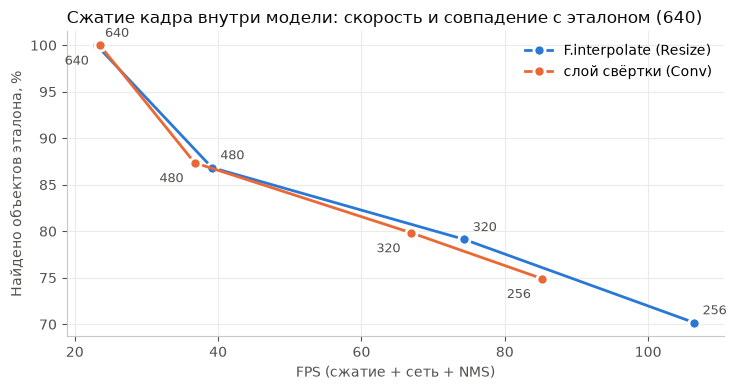

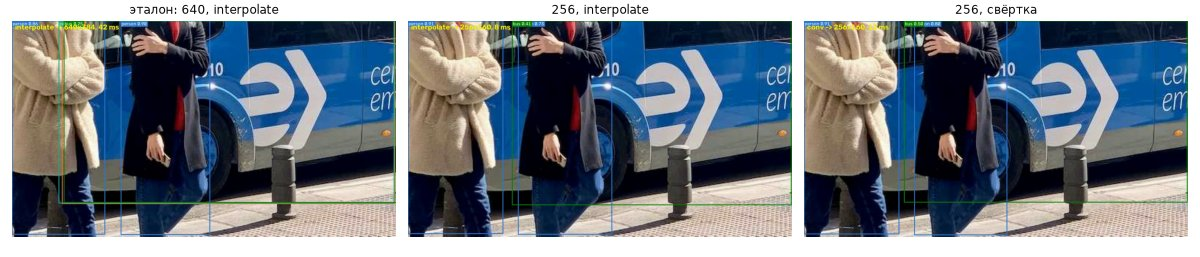

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for method, color in zip(METHODS, [ACCENT, "#eb6834"]):
    pts = sorted([r for r in rows3 if r["_m"] == method and r["_S"] > 0], key=lambda r: r["_fps"])
    x, y = [r["_fps"] for r in pts], [r["_agr"] for r in pts]
    ax.plot(x, y, color=color, lw=2, marker="o", ms=8, markeredgecolor="white", markeredgewidth=2,
            label={"interpolate": "F.interpolate (Resize)", "conv": "слой свёртки (Conv)"}[method])
    for r in pts:
        ax.annotate(f"{r['_S']}", (r["_fps"], r["_agr"]), textcoords="offset points", color=INK2, fontsize=9,
                    xytext=(6, 6) if method == "interpolate" else (-8, -14), ha="left" if method == "interpolate" else "right")
ax.set_xlabel("FPS (сжатие + сеть + NMS)")
ax.set_ylabel("Найдено объектов эталона, %")
ax.set_title("Сжатие кадра внутри модели: скорость и совпадение с эталоном (640)", loc="left", color=INK)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

S_cmp = min(s for s in COMPRESS_SIZES if s > 0)
show([video_frames(res3[REF]["video"], (0.6,))[0], video_frames(res3[(S_cmp, "interpolate")]["video"], (0.6,))[0],
      video_frames(res3[(S_cmp, "conv")]["video"], (0.6,))[0]],
     [f"эталон: {REF[0]}, interpolate", f"{S_cmp}, interpolate", f"{S_cmp}, свёртка"], cols=3, width=5)

## 4. Квантование

1. Экспорт в ONNX FP32 и FP16.
2. **Статическое INT8-квантование (post-training)** через ONNX Runtime — собственная реализация:
   калибровка по кадрам видео, формат QDQ (узлы Quantize/Dequantize — их понимают ORT, TensorRT, OpenVINO),
   веса — INT8 с отдельным масштабом на каждый канал свёртки, активации — UINT8 (схема U8S8 для x86/ARM).
   В INT8 переводится вся сеть, **кроме декодера на выходе головы**: он склеивает координаты рамок (0…640)
   и вероятности классов (0…1) в один тензор, и общий INT8-масштаб округлил бы все вероятности до нуля.
3. Для анализа ещё три варианта: «только свёртки», «весь граф» и динамическое квантование (только веса).
4. Сравнение: размер, задержка в ONNX Runtime на CPU, mAP на COCO128, совпадение детекций с FP32 на видео.
5. Если установлены — то же «родными» инструментами железа: OpenVINO (Intel/AMD CPU), TensorRT (NVIDIA), CoreML (Apple).

In [13]:
from onnxruntime.quantization import (CalibrationDataReader, CalibrationMethod, QuantFormat, QuantType,
                                      quantize_dynamic, quantize_static)
from onnxruntime.quantization.shape_inference import quant_pre_process


class FrameCalibrationReader(CalibrationDataReader):
    # Отдаёт ONNX Runtime подготовленные кадры — по ним собирается статистика активаций
    def __init__(self, blobs, input_name="images"):
        self.blobs, self.input_name, self.i = blobs, input_name, 0

    def get_next(self):
        if self.i >= len(self.blobs):
            return None
        self.i += 1
        return {self.input_name: self.blobs[self.i - 1]}

    def rewind(self):
        self.i = 0


def copy_metadata(src, dst):
    # Квантование теряет метаданные Ultralytics (имена классов, stride, imgsz) — переносим их
    m_src, m_dst = onnx.load(str(src)), onnx.load(str(dst))
    have = {p.key for p in m_dst.metadata_props}
    for p in m_src.metadata_props:
        if p.key not in have:
            m_dst.metadata_props.add(key=p.key, value=p.value)
    onnx.save(m_dst, str(dst))


def nodes_to_keep_float(model, scope):
    # head-float — всё, кроме декодера головы; convs — только операции с весами; whole — всё
    if scope == "whole":
        return []
    weighted = {"Conv", "ConvTranspose", "Gemm", "MatMul"}
    idx = [int(m.group(1)) for n in model.graph.node if (m := re.match(r"/model\.(\d+)/", n.name))]
    if scope == "convs" or not idx:
        return [n.name for n in model.graph.node if n.op_type not in weighted]
    head = f"/model.{max(idx)}/"  # последний модуль — голова Detect; её ветви свёрток cv2/cv3 квантуем
    return [n.name for n in model.graph.node if n.name.startswith(head) and not n.name.startswith(head + "cv")]


def int8_static(fp32, out, blobs, scope="head-float", method=CALIB_METHOD):
    prep = Path(out).with_name(Path(out).stem + "_prep.onnx")
    quant_pre_process(str(fp32), str(prep))  # вывод форм + оптимизация графа перед квантованием
    exclude = nodes_to_keep_float(onnx.load(str(prep)), scope)
    quantize_static(str(prep), str(out), FrameCalibrationReader(blobs), quant_format=QuantFormat.QDQ,
                    per_channel=True, activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8,
                    calibrate_method={"minmax": CalibrationMethod.MinMax, "entropy": CalibrationMethod.Entropy,
                                      "percentile": CalibrationMethod.Percentile}[method],
                    nodes_to_exclude=exclude)
    prep.unlink(missing_ok=True)
    copy_metadata(fp32, out)
    return Path(out)


def int8_dynamic(fp32, out):
    prep = Path(out).with_name(Path(out).stem + "_prep.onnx")
    quant_pre_process(str(fp32), str(prep))
    quantize_dynamic(str(prep), str(out), weight_type=QuantType.QUInt8)  # ConvInteger на CPU требует uint8-веса
    prep.unlink(missing_ok=True)
    copy_metadata(fp32, out)
    return Path(out)


fp32 = export_model("onnx", MODELS / f"{STEM}.onnx", imgsz=IMGSZ)
# FP16 экспортируем на CPU: веса FP16, вход/выход float32 — модель годится для любого рантайма (и для C++)
fp16 = export_model("onnx", MODELS / f"{STEM}_fp16.onnx", quantize=16, imgsz=IMGSZ, device="cpu")

calib = [preprocess(f)[0] for f in read_frames(VIDEO, CALIB_FRAMES)]
print(f"Калибровка: {len(calib)} кадров из {rel(VIDEO)}, метод {CALIB_METHOD}")
int8 = int8_static(fp32, MODELS / f"{STEM}_int8.onnx", calib, "head-float")
quant_variants = [("FP32 (исходная)", fp32), ("FP16", fp16), ("INT8 static, декодер во float (основной)", int8),
                  ("INT8 static, только свёртки", int8_static(fp32, MODELS / f"{STEM}_int8_convs.onnx", calib, "convs")),
                  ("INT8 static, весь граф", int8_static(fp32, MODELS / f"{STEM}_int8_wholegraph.onnx", calib, "whole")),
                  ("INT8 dynamic (только веса)", int8_dynamic(fp32, MODELS / f"{STEM}_int8_dynamic.onnx"))]
for name, p in quant_variants:
    print(f"  {name:<42} {p.name:<32} {file_mb(p):5.1f} МБ")

Калибровка: 64 кадров из data/demo.mp4, метод minmax


  FP32 (исходная)                            yolo26n.onnx                       9.9 МБ
  FP16                                       yolo26n_fp16.onnx                  5.0 МБ
  INT8 static, декодер во float (основной)   yolo26n_int8.onnx                  3.1 МБ
  INT8 static, только свёртки                yolo26n_int8_convs.onnx            3.0 МБ
  INT8 static, весь граф                     yolo26n_int8_wholegraph.onnx       3.1 МБ
  INT8 dynamic (только веса)                 yolo26n_int8_dynamic.onnx          2.9 МБ


In [14]:
def val_map(path, device="cpu"):
    m = YOLO(str(path), task="detect").val(data=VAL_DATA, imgsz=IMGSZ, batch=1, device=device, plots=False,
                                           verbose=False, project=str(RUNS / "04_quantize" / "val"),
                                           name=Path(path).stem, exist_ok=True)
    return m.box.map50, m.box.map, m.speed["inference"]


frames4 = read_frames(VIDEO, 60)
pre4 = [preprocess(f) for f in frames4]
rows4, ref4 = [], None
for name, path in quant_variants:
    sess = make_ort_session(path)  # CPU: INT8 даёт выигрыш прежде всего на процессоре
    inp = sess.get_inputs()[0].name
    for _ in range(5):
        sess.run(None, {inp: pre4[0][0]})
    ts, dets = [], []
    for (blob, r, pad), f in zip(pre4, frames4):
        with Timer() as t:
            out = sess.run(None, {inp: blob})[0]
        ts.append(t.ms)
        dets.append(postprocess(out, r=r, pad=pad, orig_shape=f.shape[:2]))
    ref4 = ref4 or dets
    row = {"Вариант": name, "Размер, МБ": f"{file_mb(path):.1f}", "Задержка CPU, мс": f"{np.mean(ts):.1f}",
           "_ms": np.mean(ts), "Совпадение с FP32 на видео, %": f"{agreement(ref4, dets):.1f}"}
    if VAL_DATA:
        m50, m, _ = val_map(path)
        row.update({"mAP50": f"{m50:.3f}", "mAP50-95": f"{m:.3f}", "_map": m})
    rows4.append(row)
    print(f"{name:<42} {np.mean(ts):6.1f} мс")
for r in rows4:
    r["Ускорение"] = f"x{rows4[0]['_ms'] / r['_ms']:.2f}"
cols4 = ["Вариант", "Размер, МБ", "Задержка CPU, мс", "Ускорение", "Совпадение с FP32 на видео, %"] + (
    ["mAP50", "mAP50-95"] if VAL_DATA else [])
table(rows4, cols4, save=RUNS / "04_quantize" / "results.md")

FP32 (исходная)                              56.6 мс


FP16                                         56.5 мс


INT8 static, декодер во float (основной)     37.5 мс


INT8 static, только свёртки                  68.7 мс


INT8 static, весь граф                       35.0 мс


INT8 dynamic (только веса)                   74.7 мс


| Вариант | Размер, МБ | Задержка CPU, мс | Ускорение | Совпадение с FP32 на видео, % | mAP50 | mAP50-95 |
|---|---|---|---|---|---|---|
| FP32 (исходная) | 9.9 | 56.6 | x1.00 | 100.0 | 0.643 | 0.477 |
| FP16 | 5.0 | 56.5 | x1.00 | 99.5 | 0.643 | 0.477 |
| INT8 static, декодер во float (основной) | 3.1 | 37.5 | x1.51 | 96.2 | 0.635 | 0.462 |
| INT8 static, только свёртки | 3.0 | 68.7 | x0.82 | 95.2 | 0.637 | 0.460 |
| INT8 static, весь граф | 3.1 | 35.0 | x1.62 | 0.0 | 0.000 | 0.000 |
| INT8 dynamic (только веса) | 2.9 | 74.7 | x0.76 | 93.3 | 0.633 | 0.447 |

'| Вариант | Размер, МБ | Задержка CPU, мс | Ускорение | Совпадение с FP32 на видео, % | mAP50 | mAP50-95 |\n|---|---|---|---|---|---|---|\n| FP32 (исходная) | 9.9 | 56.6 | x1.00 | 100.0 | 0.643 | 0.477 |\n| FP16 | 5.0 | 56.5 | x1.00 | 99.5 | 0.643 | 0.477 |\n| INT8 static, декодер во float (основной) | 3.1 | 37.5 | x1.51 | 96.2 | 0.635 | 0.462 |\n| INT8 static, только свёртки | 3.0 | 68.7 | x0.82 | 95.2 | 0.637 | 0.460 |\n| INT8 static, весь граф | 3.1 | 35.0 | x1.62 | 0.0 | 0.000 | 0.000 |\n| INT8 dynamic (только веса) | 2.9 | 74.7 | x0.76 | 93.3 | 0.633 | 0.447 |'

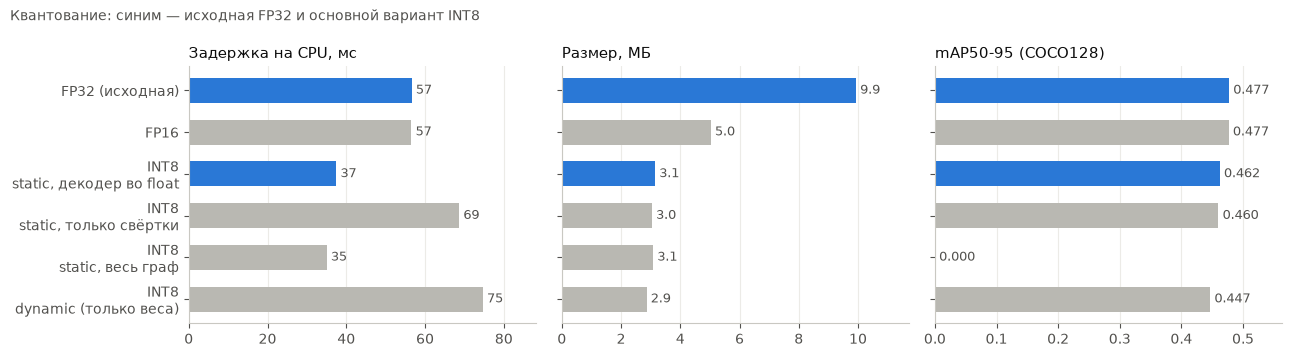

In [15]:
fig, axes = plt.subplots(1, 3 if VAL_DATA else 2, figsize=(13, 3.6), sharey=True)
labels = [r["Вариант"].replace(" (основной)", "").replace("INT8 ", "INT8\n") for r in rows4]
colors = [ACCENT if "основной" in r["Вариант"] or r["Вариант"].startswith("FP32") else MUTED for r in rows4]
metrics = [("Задержка на CPU, мс", [r["_ms"] for r in rows4], "{:.0f}"),
           ("Размер, МБ", [file_mb(p) for _, p in quant_variants], "{:.1f}")]
if VAL_DATA:
    metrics.append(("mAP50-95 (COCO128)", [r["_map"] for r in rows4], "{:.3f}"))
for ax, (title, vals, fmt) in zip(np.atleast_1d(axes), metrics):
    bars = ax.barh(labels, vals, color=colors, height=0.6)
    ax.bar_label(bars, [fmt.format(v) for v in vals], padding=3, color=INK2, fontsize=9)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.18)
np.atleast_1d(axes)[0].invert_yaxis()
fig.suptitle("Квантование: синим — исходная FP32 и основной вариант INT8", x=0.01, ha="left", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()

«Родные» инструменты железа (через `YOLO.export`). Выполняется только то, что установлено:
OpenVINO — `pip install openvino`; TensorRT — NVIDIA GPU + `pip install tensorrt`; CoreML — macOS + `pip install coremltools`.

In [16]:
if EXTRA_FORMATS == "auto":
    EXTRA_FORMATS = [f for f, ok in [("openvino", ver("openvino") != "не установлен"),
                                     ("engine", torch.cuda.is_available() and ver("tensorrt") != "не установлен"),
                                     ("coreml", platform.system() == "Darwin" and ver("coremltools") != "не установлен")] if ok]
print("Форматы:", EXTRA_FORMATS or "ничего не установлено — пропускаю")
try:  # NNCF (INT8 для OpenVINO) при импорте включает подробный лог — приглушаем
    import nncf
    nncf.set_log_level(logging.WARNING)
except ImportError:
    pass
rows4x = []
for fmt in EXTRA_FORMATS:
    dev = "0" if fmt == "engine" else "cpu"
    suffix = {"openvino": "_openvino_model", "engine": ".engine", "coreml": ".mlpackage"}[fmt]
    for q in {"openvino": [None, 8], "engine": [16, 8], "coreml": [16, 8]}[fmt]:
        tag = {None: "fp32", 16: "fp16", 8: "int8"}[q]
        try:
            kw = {"imgsz": IMGSZ, "device": dev}
            if q == 8 and fmt != "coreml":
                kw["data"] = VAL_DATA or "coco128.yaml"  # калибровочные картинки
            dst = export_model(fmt, MODELS / f"{STEM}_{tag}{suffix}", quantize=q, **kw)
            if VAL_DATA:
                m50, m, ms = val_map(dst, dev)
                rows4x.append({"Вариант": f"{fmt} {tag.upper()}", "Размер, МБ": f"{file_mb(dst):.1f}",
                               "Инференс, мс": f"{ms:.1f}", "mAP50": f"{m50:.3f}", "mAP50-95": f"{m:.3f}"})
            else:
                rows4x.append({"Вариант": f"{fmt} {tag.upper()}", "Размер, МБ": f"{file_mb(dst):.1f}"})
        except Exception as e:
            print(f"{fmt} {tag}: пропущено — {type(e).__name__}: {str(e)[:150]}")
if rows4x:
    table(rows4x, save=RUNS / "04_quantize" / "results_native.md")

Форматы: ['openvino']


| Вариант | Размер, МБ | Инференс, мс | mAP50 | mAP50-95 |
|---|---|---|---|---|
| openvino FP32 | 10.1 | 14.4 | 0.643 | 0.475 |
| openvino INT8 | 3.3 | 19.0 | 0.639 | 0.468 |

## 5. Сравнение способов ускорения

На одних и тех же кадрах для каждого бэкенда, который есть на компьютере: одинаковый препроцессинг (letterbox),
инференс, NMS; совпадение детекций с эталоном (первый бэкенд — PyTorch FP32) показывает, что ускорение не сломало
результат.

| Группа | Варианты |
|---|---|
| PyTorch | CPU, CUDA FP32/FP16, Apple MPS |
| ONNX Runtime | CPU FP32, CPU INT8 (раздел 4), CUDA EP, TensorRT EP (FP16 и INT8 Q/DQ), CoreML EP, DirectML EP, OpenVINO EP |
| OpenCV DNN | CPU; CUDA / CUDA FP16 — только OpenCV 4.x, собранный с CUDA (pip-пакеты без CUDA, в 5.x DNN пока только CPU) |
| TensorRT | `.engine` FP16 / INT8 (NVIDIA) |
| OpenVINO | FP32 / INT8 (Intel/AMD CPU) |
| CoreML | `.mlpackage` (macOS) |

Экспорт TensorRT-движка занимает несколько минут — это нормально.

In [17]:
from ultralytics.nn.autobackend import AutoBackend


class UltraRunner:
    # Любой формат, который загружает Ultralytics: .pt, .engine, OpenVINO, CoreML
    def __init__(self, weights, device="cpu", fp16=False):
        self.device = torch.device("cuda:0" if device == "0" else device)
        self.model = AutoBackend(model=str(weights), device=self.device, fp16=fp16, verbose=False)

    def __call__(self, blob):
        x = torch.from_numpy(blob).to(self.device)
        x = x.half() if self.model.fp16 else x.float()
        with torch.inference_mode():
            y = self.model(x)
        y = y[0] if isinstance(y, (list, tuple)) else y
        return y.float().cpu().numpy() if hasattr(y, "cpu") else np.asarray(y)  # .cpu() = ждём GPU


class OrtRunner:
    def __init__(self, path, provider, options=None):
        so = ort.SessionOptions()
        so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
        if provider == "DmlExecutionProvider":
            so.enable_mem_pattern, so.execution_mode = False, ort.ExecutionMode.ORT_SEQUENTIAL
        providers = [(provider, options or {})] + ([] if provider == "CPUExecutionProvider" else ["CPUExecutionProvider"])
        self.sess = ort.InferenceSession(str(path), so, providers=providers)
        if self.sess.get_providers()[0] != provider:
            raise RuntimeError(f"{provider} не запустился")
        self.name = self.sess.get_inputs()[0].name
        self.half = self.sess.get_inputs()[0].type == "tensor(float16)"

    def __call__(self, blob):
        return self.sess.run(None, {self.name: blob.astype(np.float16) if self.half else blob})[0]


class OpenCVRunner:
    def __init__(self, path, target="cpu"):
        cv2.setNumThreads(-1)  # Ultralytics при импорте делает OpenCV однопоточным — возвращаем как у ORT
        self.net = cv2.dnn.readNetFromONNX(str(path))
        if target != "cpu":
            if int(cv2.__version__.split(".")[0]) >= 5:
                raise RuntimeError("в OpenCV 5.x новый DNN-движок пока только CPU")
            self.net.setPreferableBackend(cv2.dnn.DNN_BACKEND_CUDA)
            self.net.setPreferableTarget(cv2.dnn.DNN_TARGET_CUDA_FP16 if target == "cuda-fp16" else cv2.dnn.DNN_TARGET_CUDA)

    def __call__(self, blob):
        self.net.setInput(blob)
        return self.net.forward()


cuda, mps, eps = torch.cuda.is_available(), torch.backends.mps.is_available(), ort.get_available_providers()
cv_cuda = hasattr(cv2, "cuda") and cv2.cuda.getCudaEnabledDeviceCount() > 0
trt_opts = {"trt_engine_cache_enable": True, "trt_engine_cache_path": str(MODELS / "trt_cache")}
backends = [("PyTorch CPU FP32", lambda: UltraRunner(WEIGHTS, "cpu"))]
if cuda:
    backends += [("PyTorch CUDA FP32", lambda: UltraRunner(WEIGHTS, "0")),
                 ("PyTorch CUDA FP16", lambda: UltraRunner(WEIGHTS, "0", fp16=True))]
if mps:
    backends.append(("PyTorch Apple MPS", lambda: UltraRunner(WEIGHTS, "mps")))
backends += [("ONNX Runtime CPU FP32", lambda: OrtRunner(fp32, "CPUExecutionProvider")),
             ("ONNX Runtime CPU INT8", lambda: OrtRunner(int8, "CPUExecutionProvider"))]
if "CUDAExecutionProvider" in eps:
    backends.append(("ONNX Runtime CUDA EP", lambda: OrtRunner(fp32, "CUDAExecutionProvider")))
if "TensorrtExecutionProvider" in eps:  # точность задаёт модель — так работает и TensorRT 10, и 11
    backends += [("ONNX Runtime TensorRT EP FP16", lambda: OrtRunner(fp16, "TensorrtExecutionProvider", trt_opts)),
                 ("ONNX Runtime TensorRT EP INT8 (Q/DQ)", lambda: OrtRunner(int8, "TensorrtExecutionProvider", trt_opts))]
if "CoreMLExecutionProvider" in eps:
    backends.append(("ONNX Runtime CoreML EP", lambda: OrtRunner(fp32, "CoreMLExecutionProvider", {"MLComputeUnits": "ALL"})))
if "DmlExecutionProvider" in eps:
    backends.append(("ONNX Runtime DirectML EP", lambda: OrtRunner(fp32, "DmlExecutionProvider")))
if "OpenVINOExecutionProvider" in eps:
    backends.append(("ONNX Runtime OpenVINO EP", lambda: OrtRunner(fp32, "OpenVINOExecutionProvider", {"device_type": "CPU"})))
backends.append((f"OpenCV {cv2.__version__} DNN CPU", lambda: OpenCVRunner(fp32)))
if cv_cuda:
    backends += [("OpenCV DNN CUDA", lambda: OpenCVRunner(fp32, "cuda")),
                 ("OpenCV DNN CUDA FP16", lambda: OpenCVRunner(fp32, "cuda-fp16"))]
if cuda and ver("tensorrt") != "не установлен":
    for q, tag in [(16, "fp16"), (8, "int8")]:
        kw = {"device": 0, "imgsz": IMGSZ} | ({"data": VAL_DATA or "coco128.yaml"} if q == 8 else {})
        backends.append((f"TensorRT {tag.upper()}",
                         lambda q=q, tag=tag, kw=kw: UltraRunner(export_model("engine", MODELS / f"{STEM}_{tag}.engine", q, **kw), "0")))
if ver("openvino") != "не установлен":
    for q, tag in [(None, "fp32"), (8, "int8")]:
        kw = {"imgsz": IMGSZ} | ({"data": VAL_DATA or "coco128.yaml"} if q == 8 else {})
        backends.append((f"OpenVINO {tag.upper()}", lambda q=q, tag=tag, kw=kw: UltraRunner(
            export_model("openvino", MODELS / f"{STEM}_{tag}_openvino_model", q, **kw), "cpu")))
if platform.system() == "Darwin" and ver("coremltools") != "не установлен":
    backends.append(("CoreML", lambda: UltraRunner(export_model("coreml", MODELS / f"{STEM}.mlpackage", imgsz=IMGSZ), "cpu")))
print("Будут проверены:", ", ".join(n for n, _ in backends))

Будут проверены: PyTorch CPU FP32, ONNX Runtime CPU FP32, ONNX Runtime CPU INT8, OpenCV 5.1.0 DNN CPU, OpenVINO FP32, OpenVINO INT8


In [18]:
frames5 = read_frames(VIDEO, BENCH_FRAMES, stride=1)
pre5 = [preprocess(f) for f in frames5]
with Timer() as t:
    for f in frames5:
        preprocess(f)
pre_ms = t.ms / len(frames5)

rows5, ref5 = [], None
for name, factory in backends:
    try:
        run = factory()
        for _ in range(10):
            run(pre5[0][0])
        t_inf, t_post, dets = [], [], []
        for (blob, r, pad), f in zip(pre5, frames5):
            with Timer() as t:
                out = run(blob)
            t_inf.append(t.ms)
            with Timer() as t:
                d = postprocess(out, r=r, pad=pad, orig_shape=f.shape[:2])
            t_post.append(t.ms)
            dets.append(d)
    except Exception as e:
        print(f"{name}: пропущен — {type(e).__name__}: {str(e).splitlines()[0][:150]}")
        continue
    ref5 = ref5 or dets
    total = pre_ms + np.mean(t_inf) + np.mean(t_post)
    rows5.append({"Бэкенд": name, "Инференс, мс": f"{np.mean(t_inf):.1f}", "p95, мс": f"{np.percentile(t_inf, 95):.1f}",
                  "Pre+Post, мс": f"{pre_ms + np.mean(t_post):.1f}", "FPS": f"{1000 / total:.1f}",
                  "Совпадение с эталоном, %": f"{agreement(ref5, dets):.1f}", "_inf": np.mean(t_inf)})
    print(f"{name:<40} {np.mean(t_inf):7.1f} мс   FPS {1000 / total:5.1f}")
    del run

for r in rows5:
    r["Ускорение"] = f"x{rows5[0]['_inf'] / r['_inf']:.2f}"
hw = cpu_name() + (f" + {torch.cuda.get_device_name(0)}" if cuda else "")
display(Markdown(f"**Железо:** {hw}; {platform.system()}; вход {IMGSZ}x{IMGSZ}; {len(frames5)} кадров"))
table(rows5, ["Бэкенд", "Инференс, мс", "p95, мс", "Ускорение", "Pre+Post, мс", "FPS", "Совпадение с эталоном, %"],
      save=RUNS / "05_benchmark" / "results.md")

PyTorch CPU FP32                            77.0 мс   FPS  12.5


ONNX Runtime CPU FP32                       58.1 мс   FPS  16.2


ONNX Runtime CPU INT8                       34.4 мс   FPS  26.6


OpenCV 5.1.0 DNN CPU                        54.5 мс   FPS  17.3


OpenVINO FP32                               16.1 мс   FPS  52.2


OpenVINO INT8                               20.6 мс   FPS  42.3


**Железо:** Intel(R) Xeon(R) Processor @ 2.30GHz; Linux; вход 640x640; 100 кадров

| Бэкенд | Инференс, мс | p95, мс | Ускорение | Pre+Post, мс | FPS | Совпадение с эталоном, % |
|---|---|---|---|---|---|---|
| PyTorch CPU FP32 | 77.0 | 89.8 | x1.00 | 3.0 | 12.5 | 100.0 |
| ONNX Runtime CPU FP32 | 58.1 | 68.7 | x1.33 | 3.6 | 16.2 | 100.0 |
| ONNX Runtime CPU INT8 | 34.4 | 37.3 | x2.24 | 3.1 | 26.6 | 96.6 |
| OpenCV 5.1.0 DNN CPU | 54.5 | 65.3 | x1.41 | 3.3 | 17.3 | 100.0 |
| OpenVINO FP32 | 16.1 | 18.5 | x4.78 | 3.0 | 52.2 | 99.4 |
| OpenVINO INT8 | 20.6 | 25.9 | x3.74 | 3.0 | 42.3 | 97.8 |

'| Бэкенд | Инференс, мс | p95, мс | Ускорение | Pre+Post, мс | FPS | Совпадение с эталоном, % |\n|---|---|---|---|---|---|---|\n| PyTorch CPU FP32 | 77.0 | 89.8 | x1.00 | 3.0 | 12.5 | 100.0 |\n| ONNX Runtime CPU FP32 | 58.1 | 68.7 | x1.33 | 3.6 | 16.2 | 100.0 |\n| ONNX Runtime CPU INT8 | 34.4 | 37.3 | x2.24 | 3.1 | 26.6 | 96.6 |\n| OpenCV 5.1.0 DNN CPU | 54.5 | 65.3 | x1.41 | 3.3 | 17.3 | 100.0 |\n| OpenVINO FP32 | 16.1 | 18.5 | x4.78 | 3.0 | 52.2 | 99.4 |\n| OpenVINO INT8 | 20.6 | 25.9 | x3.74 | 3.0 | 42.3 | 97.8 |'

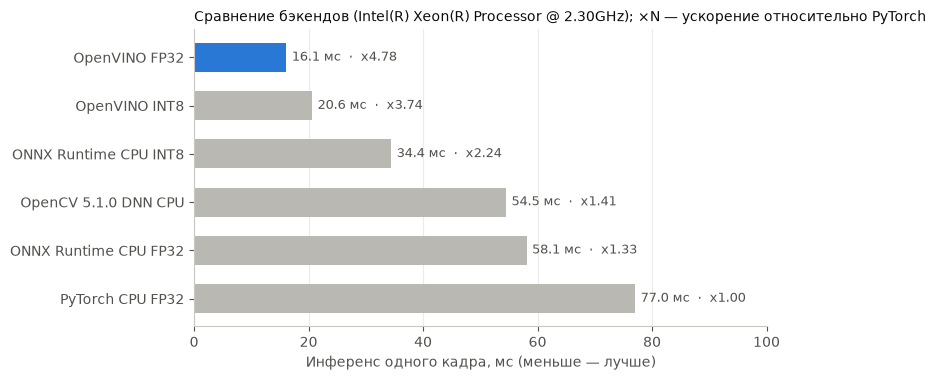

In [19]:
order = sorted(rows5, key=lambda r: r["_inf"])
fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1.2))
bars = ax.barh([r["Бэкенд"] for r in order], [r["_inf"] for r in order],
               color=[ACCENT if r is order[0] else MUTED for r in order], height=0.6)
ax.bar_label(bars, [f"{r['_inf']:.1f} мс  ·  {r['Ускорение']}" for r in order], padding=4, color=INK2, fontsize=9)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.margins(x=0.3)
ax.set_xlabel("Инференс одного кадра, мс (меньше — лучше)")
ax.set_title(f"Сравнение бэкендов ({hw}); ×N — ускорение относительно PyTorch", loc="left", color=INK, fontsize=10)
plt.tight_layout()
plt.show()

## 6. Итоги и переход к C++

Таблицы всех разделов сохранены в `runs/*/results.md` — их удобно вставить в отчёт (`THEORY.md`, раздел 11).
Часть на C++ — отдельный ноутбук **`lab1_cpp.ipynb`**: он собирает программу `cpp/yolo_video`, запускает её
на моделях ниже и сравнивает Python и C++.

In [20]:
for p in sorted(MODELS.glob(f"{STEM}*.onnx")):
    print(f"{p.name:<52} {file_mb(p):6.1f} МБ")
print(f"\nВидео для проверки: {rel(VIDEO)}")
print("Дальше: откройте lab1_cpp.ipynb и выполните Run All.")

yolo26n.onnx                                            9.9 МБ
yolo26n_compressed_1280x720_to_full.onnx               10.0 МБ
yolo26n_compressed_conv_1280x720_to_256.onnx            9.8 МБ
yolo26n_compressed_conv_1280x720_to_320.onnx            9.8 МБ
yolo26n_compressed_conv_1280x720_to_480.onnx            9.8 МБ
yolo26n_compressed_conv_1280x720_to_640.onnx            9.9 МБ
yolo26n_compressed_interpolate_1280x720_to_256.onnx     9.8 МБ
yolo26n_compressed_interpolate_1280x720_to_320.onnx     9.8 МБ
yolo26n_compressed_interpolate_1280x720_to_480.onnx     9.8 МБ
yolo26n_compressed_interpolate_1280x720_to_640.onnx     9.8 МБ
yolo26n_fp16.onnx                                       5.0 МБ
yolo26n_int8.onnx                                       3.1 МБ
yolo26n_int8_convs.onnx                                 3.0 МБ
yolo26n_int8_dynamic.onnx                               2.9 МБ
yolo26n_int8_wholegraph.onnx                            3.1 МБ

Видео для проверки: data/demo.mp4
Дальше: откройте lab